# 현실의 데이터 13: 베어링 진동으로 고장 진단

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/notebooks/datashop/13_bearing_vibration.ipynb)

**분야**: 제조 &nbsp;|&nbsp; **이 분야에서 먼저 보는 문제**: 진동 · 센서 신호 · 고장 진단 · 상태 기반 정비

> 모터 베어링에 붙인 진동 센서, 1초에 1만 2천 번. 소리만 듣고 어디가 망가졌는지 알 수 있을까?

**데이터**: CWRU Bearing Data (약 13MB). Case Western Reserve University Bearing Data Center. 모터 베어링 진동 (12 kHz) 녹음: 정상 · 내륜 · 볼 · 외륜 결함 (지름 0.007인치, 부하 0) 4개 파일.

인턴 · 산학협력 과제에서 처음 받게 될 데이터와 닮은 공개 데이터다. 데이터를 열어 보고, 아래 예시처럼 문제 하나를 정해 기준선과 비교한 뒤, 맨 끝의 **나의 다섯 칸** 을 채운다 (1주 2차시 '문제 정형화와 평가지표').

| 칸 | 이 노트북의 예시 |
|---|---|
| ① 한 행 | 진동 조각 하나 (1,024 샘플 ≈ 0.085초) |
| ② 입력 X | 조각의 통계 (RMS · 첨도 · 최댓값 …) 또는 파형 그대로 |
| ③ 출력 y | 정상 / 내륜 / 볼 / 외륜 |
| ④ 평가지표 | 정확도 (네 종류 조각 수가 비슷하다) |
| ⑤ 기준선 | 가장 흔한 종류 |

**논문 · 출처** (직접 열어 보자: 이 데이터를 누가, 왜, 어떻게 만들었나):
- [Smith & Randall (2015) Rolling element bearing diagnostics using the CWRU data: A benchmark study, MSSP](https://doi.org/10.1016/j.ymssp.2015.04.021)
- [CWRU Bearing Data Center (데이터 원본 · 실험 장치 설명)](https://engineering.case.edu/bearingdatacenter)

In [1]:
import io, os, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def download(url, path):
    """Download url to path once (skip if it already exists)"""
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    if not os.path.exists(path):
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (ML course data shop)"})
        with urllib.request.urlopen(req, timeout=600) as r, open(path, "wb") as f:
            f.write(r.read())
    return path

## 입장: 데이터 받기

`.mat` (MATLAB) 파일 4개. 각 파일 = 같은 모터를 한 상태로 10초 정도 돌린 진동 녹음. `DE` = 구동 쪽 (drive end) 센서.

In [2]:
from scipy.io import loadmat
FILES = {"normal": 97, "inner race": 105, "ball": 118, "outer race": 130}
signals = {}
for state, num in FILES.items():
    mat = loadmat(download(f"https://engineering.case.edu/sites/default/files/{num}.mat", f"data/cwru_{num}.mat"))
    key = [k for k in mat if k.endswith("DE_time")][0]
    signals[state] = mat[key].ravel()
    print(f"{state:11s} {len(signals[state]):7d} samples = {len(signals[state]) / 12000:.1f} s")

normal       243938 samples = 20.3 s
inner race   121265 samples = 10.1 s
ball         122571 samples = 10.2 s
outer race   121991 samples = 10.2 s


## 열어 보기

같은 0.05초를 네 상태로 그려 보자. 눈으로 구분이 될까?

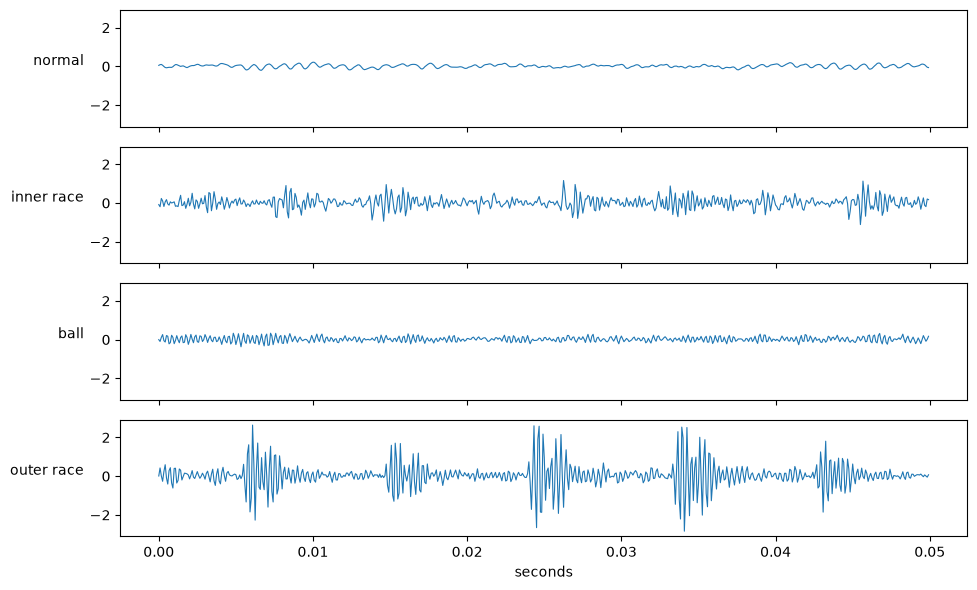

In [3]:
fig, axs = plt.subplots(4, 1, figsize=(10, 6), sharex=True, sharey=True)
t = np.arange(600) / 12000
for ax, (state, s) in zip(axs, signals.items()):
    ax.plot(t, s[:600], lw=0.8); ax.set_ylabel(state, rotation=0, ha="right")
axs[-1].set_xlabel("seconds"); plt.tight_layout(); plt.show()

## 문제 하나 골라 보기: 진동 조각 → 상태

녹음을 1,024 샘플씩 잘라 한 행으로 만든다. 조각마다 통계 6개: RMS (세기), 최댓값, 첨도 (뾰족한 충격이 있나), 왜도, 파고율 (최댓값 ÷ RMS), 영점 교차 수.
**나누기 주의**: 같은 녹음의 이웃한 조각은 거의 같다. 무작위로 섞으면 시험이 너무 쉬워진다. 그래서 녹음마다 **앞 70% 시간 → 학습, 뒤 30% → 시험**.

In [4]:
from scipy.stats import kurtosis, skew
from sklearn.ensemble import RandomForestClassifier

def chunk_features(x):
    """Six simple statistics of one vibration chunk"""
    rms = np.sqrt(np.mean(x ** 2))
    return [rms, np.max(np.abs(x)), kurtosis(x), skew(x), np.max(np.abs(x)) / rms, np.sum(np.diff(np.sign(x)) != 0)]

def make_rows(signals, size=1024, train_share=0.7):
    rows = []
    for state, s in signals.items():
        n = len(s) // size
        for k in range(n):
            rows.append(chunk_features(s[k * size:(k + 1) * size]) + [state, "train" if k < n * train_share else "test"])
    return pd.DataFrame(rows, columns=["rms", "peak", "kurtosis", "skew", "crest", "zero_cross", "state", "split"])

data = make_rows(signals)
print(data.groupby(["split", "state"]).size().unstack())
tr, te = data[data["split"] == "train"], data[data["split"] == "test"]
feats = ["rms", "peak", "kurtosis", "skew", "crest", "zero_cross"]
most_common = tr["state"].value_counts().idxmax()
m = RandomForestClassifier(300, random_state=0).fit(tr[feats], tr["state"])
print(f"\nbaseline (always '{most_common}'): accuracy {np.mean(te['state'] == most_common):.1%}")
print(f"random forest on 6 statistics : accuracy {np.mean(te['state'] == m.predict(te[feats])):.1%}")
print(data.groupby("state")[["rms", "kurtosis"]].mean().round(2))

state  ball  inner race  normal  outer race
split                                      
test     35          35      71          35
train    84          83     167          84

baseline (always 'normal'): accuracy 40.3%
random forest on 6 statistics : accuracy 100.0%
             rms  kurtosis
state                     
ball        0.14     -0.05
inner race  0.29      2.39
normal      0.07     -0.25
outer race  0.67      4.62


**관찰**: 실험실에서 한 모터로 잰 깨끗한 데이터라 아주 잘 맞는다. 현실에서는 다른 모터, 다른 부하, 공장 소음이 섞인다. **학습한 설비와 다른 설비로 시험** 하면 점수가 어떻게 될까? (이 데이터의 부하 1~3 마력 파일로 해 볼 수 있다: Smith & Randall 2015 참고)

## 다른 문제로 바꿔 보기

- **상태 기반 정비**: '어디가 망가졌나' 대신 '결함이 얼마나 큰가 (0.007 / 0.014 / 0.021 인치)' 를 맞히면 회귀 문제가 된다.
- 결함 데이터가 없는 새 설비라면? 정상 진동만으로 '평소와 다르다' 를 찾는 이상 탐지로 바꾼다.

### 나의 다섯 칸

아래 표를 직접 채워 보자. 위의 예시와 다르게 정해도 된다.

| 칸 | 내가 정한 것 |
|---|---|
| ① 한 행은 무엇? | |
| ② 입력 X (예측할 때 알 수 있는 것만) | |
| ③ 출력 y | |
| ④ 평가지표 | |
| ⑤ 기준선 | |